# Clasificación: LightGBM

### Imports y Configuración

In [1]:
import sys
sys.path.append("/workspace/src")

import pandas as pd
import matplotlib.pyplot as plt

from EstiloGraficos import aplicar_estilo

# Misma paleta y estilo que el dashboard (components/plotly_theme.py)
aplicar_estilo()

# Textos largos completos en las tablas (criterio de selección, hiperparámetros)
pd.set_option("display.max_colwidth", None)

from Modelado import (
    SEED, USAR_GPU, GPU_DISPOSITIVOS, NOMBRES_CLF, ESTRATEGIAS, N_ITER_FASE1,
    cargar_split, separar_x_y, crear_cv, dispositivo_modelo, verificar_smotenc,
    describir_espacio, ejecutar_fase1, formatear_tabla_cv, graficar_estrategias, elegir_mejor, guardar_fase1,
    formatear_hiperparametros, tabla_hiperparametros,
)

CLAVE = "lightgbm"

In [2]:
pd.Series({
    "USAR_GPU": USAR_GPU,
    "GPU detectada por librería": ", ".join(f"{lib}: {disp}" for lib, disp in GPU_DISPOSITIVOS.items() if disp) or "ninguna",
    "Dispositivo de entrenamiento": dispositivo_modelo(CLAVE),
}, name=NOMBRES_CLF[CLAVE]).to_frame()

,LightGBM
USAR_GPU,False
GPU detectada por librería,ninguna
Dispositivo de entrenamiento,CPU


### Datos: Split y Folds

In [3]:
df = pd.read_csv('/workspace/data/raw/screen_time_mental_health.csv')

df_train, _ = cargar_split(df)   # el test no se usa en esta fase
X_train, y_train = separar_x_y(df_train)
cv = crear_cv(SEED)

pd.DataFrame({
    "Filas": [len(X_train)],
    "Predictores": [X_train.shape[1]],
    "Deprimidos": [int(y_train.sum())],
    "Prevalencia": [round(y_train.mean(), 3)],
}, index=pd.Index(["Train"], name="Conjunto"))

,Filas,Predictores,Deprimidos,Prevalencia
Conjunto,,,,
Train,3848,6,630,0.164


### Estrategias de Manejo del Desbalance

Se comparan las tres estrategias de [manejo del desbalance](#mod-desbalance). En LightGBM, los pesos de clase se aplican con `class_weight="balanced"`.

In [4]:
tabla_clases, tabla_sexo = verificar_smotenc(X_train, y_train, seed=SEED)
display(tabla_clases)
display(tabla_sexo)

✓ sex solo toma los valores ['Boy', 'Girl']
✓ Clases balanceadas: {0: 3218, 1: 3218}


,Antes,Después,Sintéticos
Deprimido,,,
0,3218,3218,0
1,630,3218,2588


Deprimido,0,1
Sexo,,
Boy,1789,770
Girl,1429,2448


### Espacio de Búsqueda

Se exploraron 25 combinaciones aleatorias por estrategia. Se variaron la complejidad del modelo (entre 100 y 600 árboles, de 4 a 31 hojas, profundidad máxima de 3, 5, 7 o sin límite, y `min_child_samples` de 10 a 100), la regularización por muestreo de filas y columnas (0.6 a 1) y la tasa de aprendizaje en escala logarítmica (0.01 a 0.2).

In [5]:
describir_espacio(CLAVE).style.set_caption(f"Combinaciones por estrategia: {N_ITER_FASE1[CLAVE]}")

,Valores
Hiperparámetro,
n_estimators,entero entre 100 y 600
num_leaves,entero entre 4 y 31
max_depth,"-1, 3, 5, 7"
learning_rate,log-uniforme entre 0.01 y 0.2
min_child_samples,entero entre 10 y 100
subsample,uniforme entre 0.6 y 1
colsample_bytree,uniforme entre 0.6 y 1


### Validación Cruzada por Estrategia

In [6]:
tabla, pipelines, hiperparametros = ejecutar_fase1(CLAVE, X_train, y_train, cv, seed=SEED)

✓ Nativo (sin balanceo)  PR-AUC = 0.3965 ± 0.0521  (6 s)
✓ Pesos de clase         PR-AUC = 0.3915 ± 0.0499  (3 s)
✓ SMOTENC                PR-AUC = 0.3859 ± 0.0390  (5 s)


In [7]:
vista = formatear_tabla_cv(tabla)
vista["Tiempo (s)"] = tabla["Tiempo (s)"].round(0)
vista.rename(index=ESTRATEGIAS)

,PR-AUC,ROC-AUC,Precision,Recall,F1,Accuracy,Tiempo (s)
Estrategia,,,,,,,
Nativo (sin balanceo),0.396 ± 0.052,0.748 ± 0.032,0.630 ± 0.126,0.075 ± 0.011,0.133 ± 0.018,0.841 ± 0.004,6.0
Pesos de clase,0.392 ± 0.050,0.748 ± 0.031,0.303 ± 0.021,0.630 ± 0.065,0.409 ± 0.032,0.703 ± 0.012,3.0
SMOTENC,0.386 ± 0.039,0.747 ± 0.028,0.387 ± 0.038,0.498 ± 0.035,0.436 ± 0.037,0.788 ± 0.017,5.0


Las tres estrategias alcanzan una PR-AUC similar, de 0.396 ± 0.052 sin balanceo, 0.392 ± 0.050 con pesos de clase y 0.386 ± 0.039 con SMOTENC, con desviaciones que se solapan por completo. La ROC-AUC es prácticamente igual en los tres casos (0.748 ± 0.032, 0.748 ± 0.031 y 0.747 ± 0.028), lo que indica una capacidad discriminativa modesta y equivalente entre estrategias.

Con el umbral de 0.5, el modelo nativo obtiene la mayor precision (0.630 ± 0.126), aunque también la más variable, junto con un recall de 0.075 ± 0.011 y un F1 de 0.133 ± 0.018. Su accuracy de 0.841 ± 0.004 apenas supera la de predecir siempre “no deprimido” (1 − 0.164 = 0.836). Los pesos de clase elevan el recall a 0.630 ± 0.065 con una precision de 0.303 ± 0.021, un F1 de 0.409 ± 0.032 y una accuracy de 0.703 ± 0.012. SMOTENC se sitúa en un punto intermedio, con un recall de 0.498 ± 0.035 y una precision de 0.387 ± 0.038, y alcanza el F1 más alto (0.436 ± 0.037) con una accuracy de 0.788 ± 0.017.

In [8]:
# Mejores hiperparámetros por estrategia
tabla_hiperparametros(hiperparametros)

,colsample_bytree,learning_rate,max_depth,min_child_samples,n_estimators,num_leaves,subsample
Estrategia,,,,,,,
Nativo (sin balanceo),0.9443,0.01021,7,36,236,8,0.877
Pesos de clase,0.9443,0.01021,7,36,236,8,0.877
SMOTENC,0.9443,0.01021,7,36,236,8,0.877


Las tres estrategias seleccionaron la misma configuración: `n_estimators=236`, `num_leaves=8`, `max_depth=7`, `min_child_samples=36`, `learning_rate=0.01021`, `subsample=0.877` y `colsample_bytree=0.9443`, por lo que las diferencias en las métricas se deben únicamente a la estrategia de balanceo. Árboles de 8 hojas y una tasa de aprendizaje próxima al límite inferior del rango explorado (0.01) son coherentes con una señal simple.

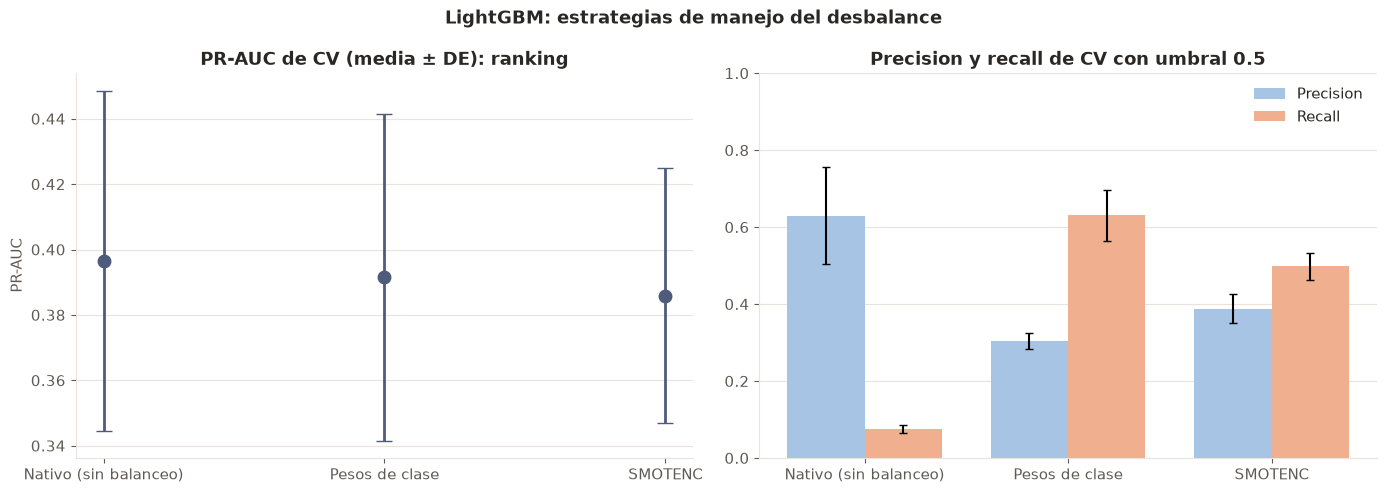

In [9]:
fig = graficar_estrategias(tabla, NOMBRES_CLF[CLAVE])
plt.show()

La gráfica confirma que las barras de PR-AUC de las tres estrategias se solapan, de modo que ni los pesos de clase ni SMOTENC mejoran la capacidad del LightGBM para ordenar los positivos por encima de los negativos. La diferencia está en el punto de operación con umbral 0.5: el nativo combina una precision de 0.630 ± 0.126 con un recall de 0.075 ± 0.011, los pesos de clase desplazan el recall a 0.630 ± 0.065 con una precision de 0.303 ± 0.021, y SMOTENC queda en una posición intermedia, con un recall de 0.498 ± 0.035 y una precision de 0.387 ± 0.038.

### Selección del Mejor Modelo LightGBM

In [10]:
estrategia_ganadora, explicacion = elegir_mejor(tabla)

pd.Series({
    "Estrategia ganadora": ESTRATEGIAS[estrategia_ganadora],
    "PR-AUC de CV": f"{tabla.loc[estrategia_ganadora, 'PR-AUC media']:.4f} ± {tabla.loc[estrategia_ganadora, 'PR-AUC DE']:.4f}",
    "Hiperparámetros": formatear_hiperparametros(hiperparametros[estrategia_ganadora]),
    "Criterio": explicacion,
}, name=NOMBRES_CLF[CLAVE]).to_frame()

,LightGBM
Estrategia ganadora,Nativo (sin balanceo)
PR-AUC de CV,0.3965 ± 0.0521
Hiperparámetros,"colsample_bytree=0.9443, learning_rate=0.01021, max_depth=7, min_child_samples=36, n_estimators=236, num_leaves=8, subsample=0.877"
Criterio,Se elige 'nativo': tiene la mayor PR-AUC media de CV (0.3965 ± 0.0521).


Se selecciona la estrategia nativa por presentar la mayor PR-AUC media (0.3965 ± 0.0521). Su ventaja sobre los pesos de clase (0.0050) y SMOTENC (0.0106) es inferior a la desviación entre folds, por lo que las tres estrategias son equivalentes en la práctica. Su recall de 0.075 ± 0.011 con umbral 0.5 no condiciona la selección, que se basa en la PR-AUC, y el umbral de operación se optimiza en la fase 3.

### Guardado

In [11]:
ganador = guardar_fase1(
    CLAVE, tabla, estrategia_ganadora, pipelines[estrategia_ganadora],
    hiperparametros[estrategia_ganadora], explicacion,
)